In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn nltk wordcloud

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
import re

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from wordcloud import WordCloud

In [3]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [4]:
df = pd.read_csv("/content/student_feedback_dataset.csv")

print(df.head())
print(df.shape)
print(df.info())

   Feedback_ID Program        Department              Subject  \
0            1     MCA  Computer Science  Database Management   
1            2     MCA  Computer Science   Python Programming   
2            3     MCA    Data Analytics     Machine Learning   
3            4     MCA    Data Analytics          Data Mining   
4            5     MCA  Computer Science      Web Development   

                                            Feedback Sentiment  
0  The teacher explains concepts clearly and uses...  Positive  
1  The classes are interesting, but more coding p...   Neutral  
2  The teaching is good, but the syllabus is comp...  Negative  
3  The faculty encourages questions and classroom...  Positive  
4  There are not enough practical sessions. We ne...  Negative  
(40, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Feedback_ID  40 non-nu

In [5]:
print(df["Sentiment"].value_counts())

Sentiment
Positive    15
Negative    14
Neutral     11
Name: count, dtype: int64


In [6]:
print(df.isnull().sum())

Feedback_ID    0
Program        0
Department     0
Subject        0
Feedback       0
Sentiment      0
dtype: int64


In [7]:
df = df.dropna(subset=["Feedback"])

In [8]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()

    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Remove numbers
    text = re.sub(r"\d+", "", text)

    # Tokenization
    words = text.split()

    # Remove stopwords
    words = [word for word in words if word not in stop_words]

    # Lemmatization
    words = [lemmatizer.lemmatize(word) for word in words]

    return " ".join(words)

df["Clean_Feedback"] = df["Feedback"].apply(preprocess)

print(df[["Feedback", "Clean_Feedback"]].head())

                                            Feedback  \
0  The teacher explains concepts clearly and uses...   
1  The classes are interesting, but more coding p...   
2  The teaching is good, but the syllabus is comp...   
3  The faculty encourages questions and classroom...   
4  There are not enough practical sessions. We ne...   

                                      Clean_Feedback  
0  teacher explains concept clearly us practical ...  
1           class interesting coding practice needed  
2  teaching good syllabus completed quickly topic...  
3  faculty encourages question classroom discussi...  
4  enough practical session need handson activity...  


In [10]:
X = df["Clean_Feedback"]
y = df["Sentiment"]

tfidf = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2)
)

X_tfidf = tfidf.fit_transform(X)

print(X_tfidf.shape)

(40, 380)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [12]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [13]:
y_pred = model.predict(X_test)

In [14]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.75


In [15]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Neutral", "Positive"]
))

              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00         3
     Neutral       0.00      0.00      0.00         2
    Positive       0.60      1.00      0.75         3

    accuracy                           0.75         8
   macro avg       0.53      0.67      0.58         8
weighted avg       0.60      0.75      0.66         8



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


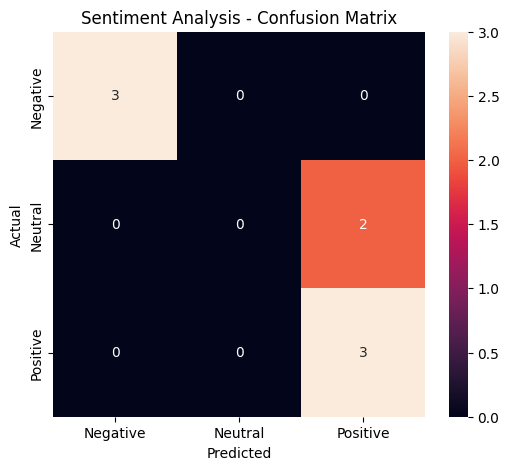

In [16]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Sentiment Analysis - Confusion Matrix")

plt.show()

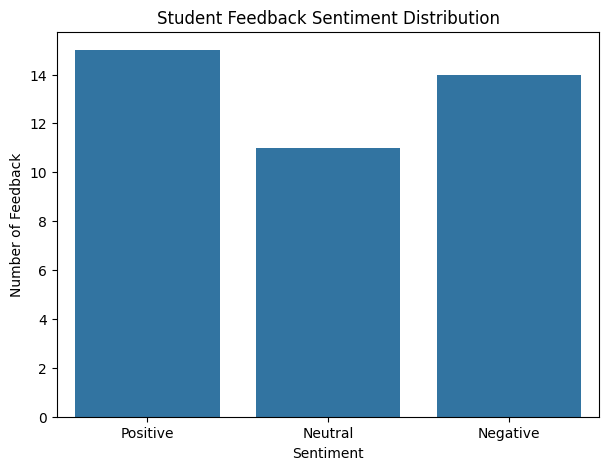

In [17]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Sentiment"
)

plt.title("Student Feedback Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Feedback")

plt.show()

In [19]:
subject_sentiment = pd.crosstab(
    df["Subject"],
    df["Sentiment"]
)

print(subject_sentiment)

Sentiment                       Negative  Neutral  Positive
Subject                                                    
Artificial Intelligence                0        0         2
Big Data Analytics                     1        1         0
Business Analytics                     0        1         1
Cloud Computing                        0        0         2
Computer Networks                      2        0         0
Cyber Security                         1        1         0
Data Mining                            0        0         2
Data Structures                        0        2         0
Data Visualization                     0        0         2
Database Management                    1        0         1
Java Programming                       1        0         1
Machine Learning                       1        0         1
Mobile Application Development         1        0         1
Natural Language Processing            1        1         0
Operating Systems                      2

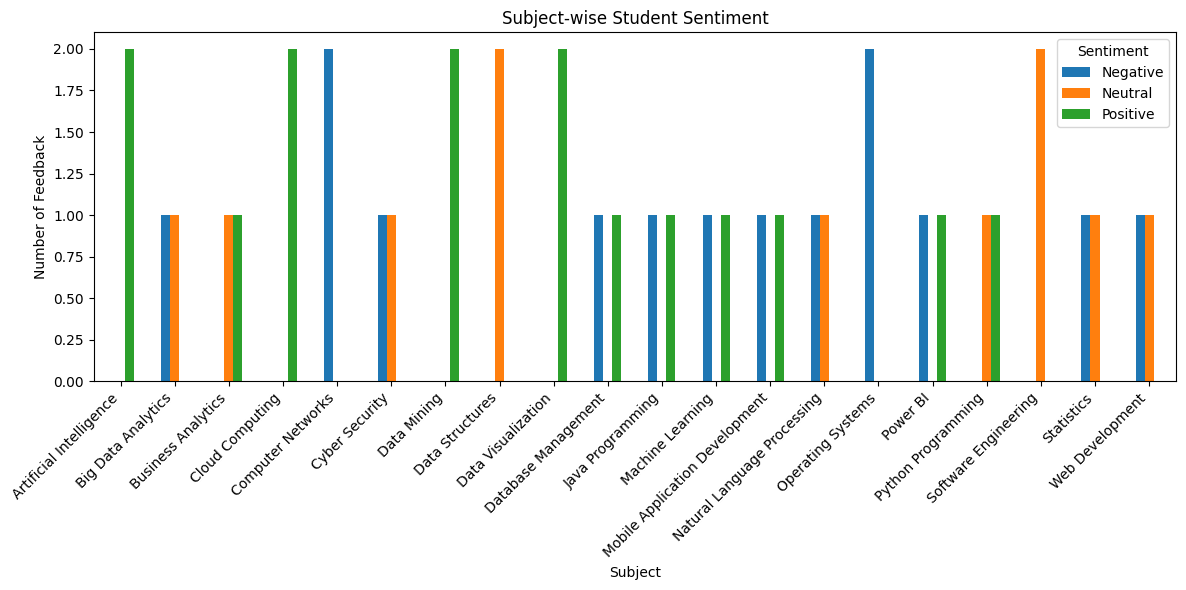

In [20]:
subject_sentiment.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Subject-wise Student Sentiment")
plt.xlabel("Subject")
plt.ylabel("Number of Feedback")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Sentiment")

plt.tight_layout()
plt.show()

In [21]:
negative_feedback = df[
    df["Sentiment"] == "Negative"
]

print(negative_feedback[[
    "Subject",
    "Feedback"
]])

                           Subject  \
2                 Machine Learning   
4                  Web Development   
7                         Power BI   
9                Operating Systems   
11               Computer Networks   
16                  Cyber Security   
18  Mobile Application Development   
20             Database Management   
23                      Statistics   
26                Java Programming   
29               Operating Systems   
31               Computer Networks   
34              Big Data Analytics   
39     Natural Language Processing   

                                             Feedback  
2   The teaching is good, but the syllabus is comp...  
4   There are not enough practical sessions. We ne...  
7   The lab computers are sometimes slow and softw...  
9   The lectures are too fast. I cannot take notes...  
11  The classroom activities are useful, but inter...  
16  The subject is difficult because there are few...  
18  The lab sessions are useful, but 

In [22]:
negative_text = " ".join(
    negative_feedback["Clean_Feedback"]
)

words = negative_text.split()

word_frequency = pd.Series(words).value_counts()

print(word_frequency.head(20))

difficult       5
practical       4
time            4
lab             4
subject         4
need            3
session         3
would           2
make            2
updated         2
useful          2
topic           2
example         2
enough          2
take            2
sometimes       2
note            2
connectivity    2
activity        2
classroom       2
Name: count, dtype: int64


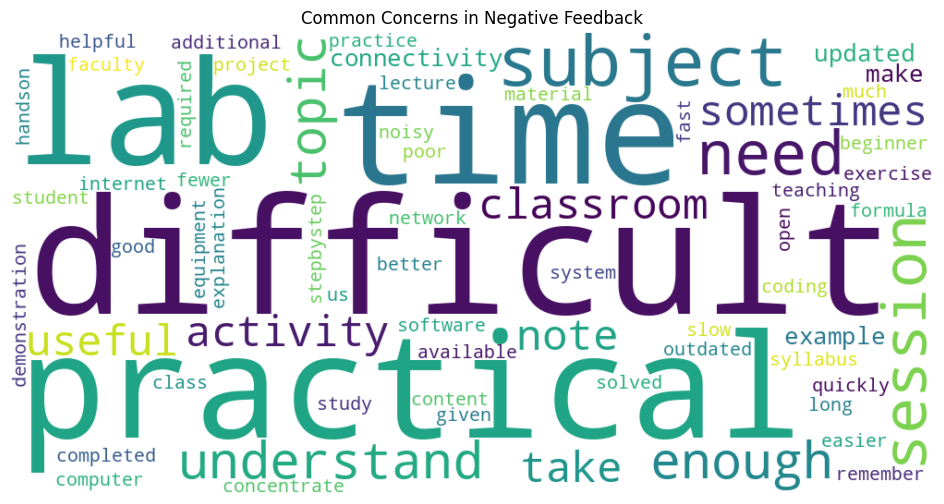

In [23]:
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(negative_text)

plt.figure(figsize=(12, 6))

plt.imshow(wordcloud, interpolation="bilinear")

plt.axis("off")

plt.title("Common Concerns in Negative Feedback")

plt.show()

In [25]:
new_feedback = [
    "The teacher explains concepts very clearly and provides excellent practical examples.",
    "The classes are too fast and we need more practical sessions.",
    "The subject is okay but more examples should be provided."
]

new_clean = [preprocess(text) for text in new_feedback]

new_vector = tfidf.transform(new_clean)

predictions = model.predict(new_vector)

for text, prediction in zip(new_feedback, predictions):
    print("Feedback:", text)
    print("Predicted Sentiment:", prediction)
    print()

Feedback: The teacher explains concepts very clearly and provides excellent practical examples.
Predicted Sentiment: Positive

Feedback: The classes are too fast and we need more practical sessions.
Predicted Sentiment: Negative

Feedback: The subject is okay but more examples should be provided.
Predicted Sentiment: Negative

